# **트리 모델**

---



**(코랩에서)한글 폰트 지정하는 방법**

In [ ]:
# 코랩에서 실행
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import shutil

# ── 1. 나눔 폰트 설치 ──────────────────────────────────────────
!apt-get install -y fonts-nanum > /dev/null 2>&1

# ── 2. matplotlib 캐시 디렉터리 삭제 ──────────────────────────
shutil.rmtree(mpl.get_cachedir(), ignore_errors=True)

# ── 3. 폰트 등록  ───────────────────────────────────
font_path = '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf'
fm.fontManager.addfont(font_path)
font_name = fm.FontProperties(fname=font_path).get_name()
plt.rcParams['font.family'] = font_name
plt.rcParams['font.size'] = 12
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.figsize'] = (6, 4)



---




- <a href="#의사결정나무">의사결정나무(Decision tree)</a>
- <a href="#랜덤포레스트">랜덤포레스트(Random Forest)</a>
- <a href="#그라디언트부스팅">그라디언트 부스팅(gradient boosting)</a>

---------------------

## ⏺️ <a name="의사결정나무">의사결정나무(Decision tree)</a>

- sklearn.tree : https://scikit-learn.org/stable/api/sklearn.tree.html
- DecisionTreeClassifier : https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html

### 2) 의사결정나무 실습하기 (DecisionTreeClassifier)

#### (1) 데이터 준비하기

In [ ]:
# 라이브러리 불러오기 (numpy, pandas, train_test_split)
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# 데이터 불러오기
df = pd.read_csv("국민건강보험공단_건강검진정보_20211229.CSV", encoding = 'cp949')
# 트리 예시를 만들기 위해서 일부 특성만 추출
sample_df = df[['신장(5Cm단위)','성별코드', '체중(5Kg 단위)','음주여부']]

# 샘플 데이터 중 상위 10개 추출하기
sample_df[:10]

,신장(5Cm단위),성별코드,체중(5Kg 단위),음주여부
0,165.0,1.0,60.0,0.0
1,150.0,2.0,65.0,0.0
2,155.0,2.0,55.0,0.0
3,160.0,1.0,70.0,0.0
4,155.0,2.0,50.0,0.0
5,185.0,1.0,85.0,1.0
6,165.0,1.0,80.0,1.0
7,160.0,1.0,65.0,0.0
8,150.0,2.0,50.0,0.0
9,150.0,2.0,45.0,0.0


#### (2) 데이터 전처리하기

In [ ]:
# info 정보로 결측치(Null) 확인하기
print("Info 정보 확인")
sample_df.info()

Info 정보 확인
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 170577 entries, 0 to 170576
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   신장(5Cm단위)   170576 non-null  float64
 1   성별코드        170576 non-null  float64
 2   체중(5Kg 단위)  170576 non-null  float64
 3   음주여부        170543 non-null  float64
dtypes: float64(4)
memory usage: 5.2 MB


In [ ]:
# 100만개 데이터 중 결측치 196개, 결측치가 포함된 행 삭제하기
sample = sample_df.dropna()

# 결측치(Null) 다시 확인하기
print("Drop 후 Info 정보 확인")
sample.info()

Drop 후 Info 정보 확인
<class 'pandas.core.frame.DataFrame'>
Index: 170543 entries, 0 to 170575
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   신장(5Cm단위)   170543 non-null  float64
 1   성별코드        170543 non-null  float64
 2   체중(5Kg 단위)  170543 non-null  float64
 3   음주여부        170543 non-null  float64
dtypes: float64(4)
memory usage: 6.5 MB


In [ ]:
# 원-핫 인코딩을 위해 데이터를 object 형태로 변경하기
sample = sample.astype('str')

# 원하는 타입만 변경할 경우
# sample['음주여부'] = sample['음주여부'].astype('str')
# sample = sample.astype({'음주여부':'str'})

In [ ]:
sample.info()

<class 'pandas.core.frame.DataFrame'>
Index: 170543 entries, 0 to 170575
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   신장(5Cm단위)   170543 non-null  object
 1   성별코드        170543 non-null  object
 2   체중(5Kg 단위)  170543 non-null  object
 3   음주여부        170543 non-null  object
dtypes: object(4)
memory usage: 6.5+ MB


In [ ]:
# 음주 여부 학습 데이터 구성하기
X=sample.drop('음주여부', axis=1)

# label(결과, Y) 생성하기
y=sample.음주여부


# label 데이터의 편향성 확인하기
y.value_counts()

,count
음주여부,
1.0,99560
0.0,70983


In [ ]:
# 학습/검증 데이터 분리하기
x_train, x_valid, y_train, y_valid = train_test_split(
    X, y,
    test_size=0.2,
    shuffle=True,
    random_state=34
)

#### (3) 의사결정나무 모델링하기

In [ ]:
# 의사결정나무 모델 불러오기
from sklearn.tree import DecisionTreeClassifier

# 의사결정나무 모델 생성하기
dt = DecisionTreeClassifier(random_state = 1001,
                            max_depth=2
                           )

# 의사결정나무 학습하기
dt_model = dt.fit(x_train, y_train)


# 학습 데이터 정확도 확인하기
print("학습 정확도 = ", dt_model.score(x_train, y_train))

# 검증 데이터 정확도 확인하기
print("검증 정확도 = ", dt_model.score(x_valid, y_valid))

학습 정확도 =  0.6629212659600979
검증 정확도 =  0.6603535723709285


#### (4) 의사결정나무 그래프 그리기

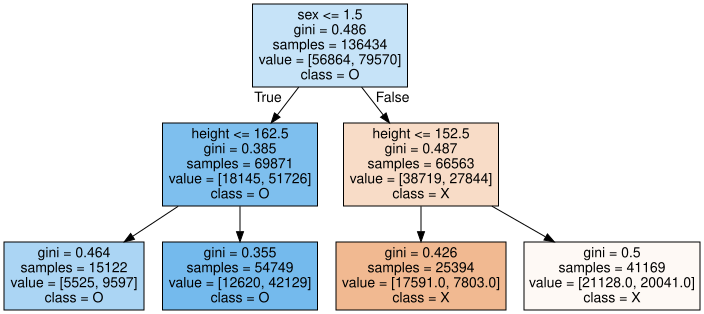

In [ ]:
# 그래프 라이브러리(matplotlib.pyplot) 불러오기
import matplotlib.pyplot as plt

# 트리 모양 그래프 작성을 위한 라이브러리 설치하기(코랩에는 이미 설치됨)
#!pip install graphviz
# 그래프 라이브러리(grphviz) 불러오기
import graphviz
# 사이킷런의 graphviz 지원 모듈 불러오기
from sklearn.tree import export_graphviz

# 그래프 생성하기
tree_graph = graphviz.Source(export_graphviz(dt_model,
                                class_names=["X","O"],
                                feature_names=[ 'height', 'sex','weight'],
                                impurity=True,
                                filled=True))
# 그래프 출력하기
# (참고) 에러 발생시 사이트 참조 : https://highschoolfree.tistory.com/76
tree_graph

In [ ]:
# 그래프 파일 저장하기
tree_graph.render('tree_depth5', format="png")

'tree_depth5.png'

### 3) 불순도 알아보기

In [ ]:
# 불순도 함수 생성하기
def gini(x):
    n = x.sum()
    gini_sum = 0
    for key in x.keys():
        gini_sum = gini_sum  +  (x[key] / n ) * (x[key] / n )
    gini = 1 - gini_sum
    return gini

- 지니계수 확인하기

In [ ]:
# 데이터 준비하기(불순도 예시)
과일바구니1 = ['사과']*9
과일바구니2 = ['사과', '바나나','사과', '바나나','바나나','바나나', '복숭아','복숭아','복숭아']
과일바구니3 = ['사과', '바나나','사과', '바나나','사과','복숭아', '복숭아','사과','복숭아']

print(pd.DataFrame(과일바구니1).value_counts())
print(pd.DataFrame(과일바구니2).value_counts())
print(pd.DataFrame(과일바구니3).value_counts())
print('\n지니계수 출력-----------------')
print(round(gini(pd.DataFrame(과일바구니1).value_counts()),3))
print(round(gini(pd.DataFrame(과일바구니2).value_counts()),3))
print(round(gini(pd.DataFrame(과일바구니3).value_counts()),3))


0 
사과    9
Name: count, dtype: int64
0  
바나나    4
복숭아    3
사과     2
Name: count, dtype: int64
0  
사과     4
복숭아    3
바나나    2
Name: count, dtype: int64

지니계수 출력-----------------
0.0
0.642
0.642


### [확인 문제] 하이퍼파라미터 설정

#### [Quiz 1] 앞에서 활용했던 데이터(국민건강보험공단~) 의 (sample_df : 음주여부 예측) 컬럼을 활용하여 max_depth 파라미터를 1, 15, 30으로 놓고 각각의 모델을 만들어보고 validation score가 작게 나오는  max_dept 수치를 작성하세요.(단, random_state는 1001 고정)


In [ ]:
#for 문제 직접 리스트를 넣어서 구현하기
for depth in [1,15,30]:
    dt = DecisionTreeClassifier(random_state = 1001,
                            max_depth=depth,
                           )
    dt_model = dt.fit(x_train, y_train)
    print(f'''max_depth {depth}일때 train 정확도:{dt_model.score(x_train, y_train):.2f}, validation 정확도:{dt_model.score(x_valid, y_valid):.2f}''')

max_depth 1일때 train 정확도:0.66, validation 정확도:0.66
max_depth 15일때 train 정확도:0.68, validation 정확도:0.67
max_depth 30일때 train 정확도:0.68, validation 정확도:0.67


#### [Quiz 2]. max_feature 파라미터 값을 1,2,3으로 하는 각각 모델을 만들고 validation Score가 가장 높은 max_feature를 작성하세요. (단, random_state는 1001로 고정하고, max_depth에 대해 앞에서 가장 작은 max_depth 고정 후 결과 산출)

In [ ]:
# 리스트를 별도로 만들어서 max_feature 변경하고 결과 산출
for feature in [1,2,3]:
    dt = DecisionTreeClassifier(random_state = 1001,
                                max_depth=1,
                                max_features = feature,
                           )
    dt_model = dt.fit(x_train, y_train)
    print(f'''max_feature {feature}일때 train 정확도:{dt_model.score(x_train, y_train):.2f}, validation 정확도:{dt_model.score(x_valid, y_valid):.2f}''')

max_feature 1일때 train 정확도:0.67, validation 정확도:0.67
max_feature 2일때 train 정확도:0.66, validation 정확도:0.66
max_feature 3일때 train 정확도:0.66, validation 정확도:0.66


### **[LLM 실습] 의사결정나무 규칙을 LLM이 설명하게 하기**

- ① Iris 데이터로 의사결정나무를 학습하고 → ② 학습된 트리 규칙을 텍스트로 추출한 뒤 → ③ 그 규칙을 Gemini에게 전달해 사람이 이해하기 쉽게 설명하게 하는 실습

In [ ]:
# ============================================================
# 0. 필요한 라이브러리 설치
# ============================================================

# !pip install -q -U google-genai scikit-learn


# ============================================================
# 1. 라이브러리 불러오기
# ============================================================

from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import accuracy_score

from google import genai
from google.colab import userdata


# ============================================================
# 2. Iris 데이터 불러오기
# ============================================================

X, y = load_iris(
    return_X_y=True,
    as_frame=True
)

iris = load_iris()

print("Feature 이름:")
print(list(X.columns))

print("\n클래스:")
print(iris.target_names)


# ============================================================
# 3. 의사결정나무 학습
# ============================================================
# max_depth=3
# → 트리 깊이를 3단계로 제한
# → 규칙이 너무 복잡해지는 것을 방지

tree = DecisionTreeClassifier(
    max_depth=3,
    random_state=0
)

tree.fit(X, y)


# ============================================================
# 4. 학습 정확도 확인
# ============================================================

pred = tree.predict(X)

accuracy = accuracy_score(
    y,
    pred
)

print("\n학습 정확도:")
print(round(accuracy, 4))


# ============================================================
# 5. 의사결정나무 규칙을 텍스트로 추출
# ============================================================

rules = export_text(
    tree,
    feature_names=list(X.columns)
)

print("\n==============================")
print("의사결정나무가 학습한 규칙")
print("==============================")

print(rules)


# ============================================================
# 6. Gemini API 연결
# ============================================================

api_key = userdata.get("GEMINI_API_KEY")

if api_key is None:
    raise ValueError(
        "Colab Secrets에 GEMINI_API_KEY를 등록해주세요."
    )

client = genai.Client(
    api_key=api_key
)


Feature 이름:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

클래스:
['setosa' 'versicolor' 'virginica']

학습 정확도:
0.9733

의사결정나무가 학습한 규칙
|--- petal width (cm) <= 0.80
|   |--- class: 0
|--- petal width (cm) >  0.80
|   |--- petal width (cm) <= 1.75
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- class: 1
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- class: 2
|   |--- petal width (cm) >  1.75
|   |   |--- petal length (cm) <= 4.85
|   |   |   |--- class: 2
|   |   |--- petal length (cm) >  4.85
|   |   |   |--- class: 2



In [ ]:
# ============================================================
# 7. 의사결정나무 규칙을 Gemini에게 설명 요청
# ============================================================

prompt = f"""
아래는 Iris 꽃 품종을 분류하기 위해
Decision Tree가 학습한 규칙입니다.

Iris 품종은 다음과 같습니다.

0 = Setosa
1 = Versicolor
2 = Virginica

[학습된 의사결정나무 규칙]

{rules}

이 규칙을 머신러닝을 처음 배우는 대학생에게
쉽게 설명해주세요.

다음 형식으로 설명해주세요.

1. 이 트리에서 가장 중요한 분류 기준은 무엇인가?
2. Setosa를 구분하는 규칙을 한 줄로 설명
3. Versicolor를 구분하는 규칙을 한 줄로 설명
4. Virginica를 구분하는 규칙을 한 줄로 설명
5. 이 의사결정나무가 틀릴 수 있는 경우를 쉽게 설명
6. 전체 의사결정 과정을 3줄로 요약

전문 용어를 최소화하고 쉽게 설명해주세요.
"""


# ============================================================
# 8. Gemini 실행
# ============================================================

# MODEL = "gemini-3.8-flash"
MODEL = "gemini-3-flash-preview"

response = client.models.generate_content(
    model=MODEL,
    contents=prompt
)


# ============================================================
# 9. Gemini 설명 출력
# ============================================================

print("\n\n==============================")
print("Gemini가 설명한 의사결정나무")
print("==============================\n")

print(response.text)



Gemini가 설명한 의사결정나무

머신러닝의 가장 직관적인 모델인 **의사결정나무(Decision Tree)**는 마치 '스무고개' 게임과 같습니다. 제시된 규칙을 바탕으로 대학생의 눈높이에서 쉽게 설명해 드릴게요.

---

### 1. 이 트리에서 가장 중요한 분류 기준은 무엇인가?
가장 처음에 등장하여 데이터를 크게 갈라놓는 **'꽃잎의 너비(petal width)'**입니다. 이 기준 하나만으로도 Setosa 품종을 완벽하게 걸러낼 수 있기 때문에 가장 중요한 정보라고 할 수 있습니다.

### 2. Setosa를 구분하는 규칙을 한 줄로 설명
꽃잎의 너비가 0.8cm 이하이기만 하면 아주 쉽게 **Setosa**로 분류됩니다.

### 3. Versicolor를 구분하는 규칙을 한 줄로 설명
꽃잎 너비가 0.8cm보다 크고 1.75cm 이하이면서, 동시에 꽃잎의 길이가 4.95cm 이하일 때 **Versicolor**가 됩니다.

### 4. Virginica를 구분하는 규칙을 한 줄로 설명
꽃잎 너비가 1.75cm를 넘거나, 설령 너비가 그보다 좁더라도 꽃잎 길이가 4.95cm보다 길면 **Virginica**로 분류합니다.

### 5. 이 의사결정나무가 틀릴 수 있는 경우를 쉽게 설명
이 모델은 '0.8cm'나 '1.75cm' 같은 **딱딱한 경계선**을 기준으로 판단합니다. 만약 아주 드물게 꽃잎 너비가 1.76cm인데 실제로는 Versicolor인 '예외적인 꽃'이 있다면, 이 나무는 단순히 숫자가 기준을 넘었다는 이유만으로 잘못된 판단(Virginica)을 내릴 수 있습니다.

### 6. 전체 의사결정 과정을 3줄로 요약
1. 먼저 **꽃잎의 너비**를 보고 아주 좁으면(0.8cm 이하) 바로 **Setosa**로 결정한다.
2. 너비가 중간 정도라면 **꽃잎의 길이**를 추가로 확인하여 짧으면 **Versicolor**, 길면 **Virginica**로 나눈다.
3. 꽃잎의 너비가 아주 넓다면(1.75cm 초과) 길이와 상관없이 대

---------------------------

## ⏺️ <a name="랜덤포레스트">랜덤포레스트(Random Forest)</a>

- sklearn.ensemble : https://scikit-learn.org/stable/api/sklearn.ensemble.html  
- RandomForestClassifier : https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html  

### 2) 랜덤포레스트 실습하기

#### (1) 데이터 준비하기

In [ ]:
# tensorflow 라이브러리 설치하기
#!pip install tensorflow --user

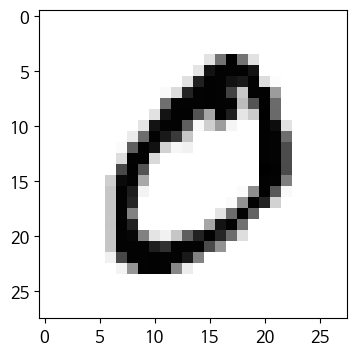

In [ ]:
# tensorflow에서 제공하는 데이터셋 mnist 불러오기
from tensorflow.keras.datasets.mnist import load_data

# load_data로 데이터 할당하기
(x_train, y_train), (x_test, y_test) = load_data()


# 샘플 데이터 matplotlib 그래프로 나타내보기
import matplotlib.pyplot as plt
plt.imshow(x_train[1], cmap='Greys')
plt.show()

In [ ]:
# 손 글씨 데이터는 이미지라 3차원 행렬
print("변경 전 = ",x_train.shape)

# 3차원 행렬을 2차원으로 변경하기
X_train = x_train.reshape(-1, 784)
X_test = x_test.reshape(-1, 784)

# 변경 결과 확인하기
print("변경 후 = ",X_train.shape)

변경 전 =  (60000, 28, 28)
변경 후 =  (60000, 784)


#### (2) 의사결정나무 모델링하기

In [ ]:
# 필요 라이브러리 불러오기(의사결정나무, 랜덤포레스트)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier


# 의사결정나무 학습하기
dtc = DecisionTreeClassifier(random_state=0)
dtc.fit(X_train, y_train)


# 의사결정나무 결과확인하기
acc_train_dtc = dtc.score(X_train,y_train)
acc_test_dtc = dtc.score(X_test,y_test)

print(f'''학습결과 = {acc_train_dtc},검증결과 = {acc_test_dtc} ''')

학습결과 = 1.0,검증결과 = 0.8781 


#### (3) 랜덤포레스트 모델링 및 결과 비교하기

의사결정나무: train_acc = 1.0, test_acc = 0.878
랜덤포레스트: train_acc = 1.0, test_acc = 0.971


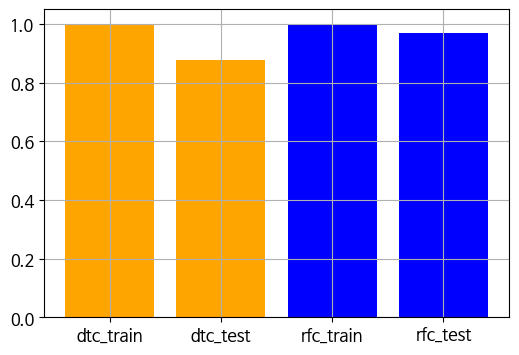

In [ ]:
# 랜덤포레스트 학습하기
rfc = RandomForestClassifier(random_state=0)
rfc.fit(X_train, y_train)


# 랜덤포레스트 결과 보기
acc_train_rfc = rfc.score(X_train,y_train)
acc_test_rfc = rfc.score(X_test,y_test)

# 학습 결과 수치로 출력하기
print(f"""의사결정나무: train_acc = {round(acc_train_dtc,3)}, test_acc = {round(acc_test_dtc,3)}""")
print(f"""랜덤포레스트: train_acc = {round(acc_train_rfc,3)}, test_acc = {round(acc_test_rfc,3)}""")


# 랜덤포레스트 결과를 토대로 비교 그래프 그리기
import matplotlib.pyplot as plt
# x 축 정의하기
acc_list_x = ['dtc_train', 'dtc_test', 'rfc_train', 'rfc_test']
# y 축 정의
acc_list_y = [acc_train_dtc, acc_test_dtc, acc_train_rfc, acc_test_rfc]
# 막대그래프 차트 색 정의하기
colors = ['orange', 'orange' , 'blue', 'blue']
# 막대그래프 설정하기
plt.bar(acc_list_x, acc_list_y, color=colors)
# 화면 출력하기
plt.grid(True)
plt.show()

### 3) 랜덤포레스트와 의사결정나무 비교하기

In [ ]:
# 의사결정나무 결과와 동일하게 랜덤포레스트 구성하기
rft = RandomForestClassifier(
    random_state=0,
    # 나무 개수를 1개로 설정하기
    n_estimators=1,
    # max_feature는 의사결정나무 기준으로 변경하기
    max_features=None,
    # 부트스트랩 샘플링은 OFF하기
    bootstrap=False,
)
rft.fit(X_train, y_train)


# 학습 결과 저장하기
acc_train_rfc = rft.score(X_train,y_train)
acc_test_rfc = rft.score(X_test,y_test)
acc_train_dtc = dtc.score(X_train,y_train)
acc_test_dtc = dtc.score(X_test,y_test)

#의사결정나무 & 랜덤포레스트가 유사한 결과를 출력하는지 비교하기
print(f"""의사결정나무: train_acc = {round(acc_train_dtc,3)}, test_acc = {round(acc_test_dtc,3)}""")
print(f"""랜덤포레스트: train_acc = {round(acc_train_rfc,3)}, test_acc = {round(acc_test_rfc,3)}""")

의사결정나무: train_acc = 1.0, test_acc = 0.878
랜덤포레스트: train_acc = 1.0, test_acc = 0.877


### [확인 문제]

#### [Quiz 1] Max_features 의 값을 40, 50, 60 으로 변경해보고 가장 좋은 결과값을 작성 하세요. (단, random_state는 0으로 고정)

In [ ]:
max_features = [40, 50, 60]
for max_feature in max_features:
    print(f'max_features={max_feature} 로 설정된 학습을 진행합니다.')
    rfc = RandomForestClassifier(max_features = max_feature,
                                 n_jobs= -1,
                                 random_state = 0)
    rfc.fit(X_train, y_train)
    acc_train_rfc = rfc.score(X_train,y_train)
    acc_test_rfc = rfc.score(X_test,y_test)
    print(f"""max_features={max_feature} 일 때 train_acc={round(acc_train_rfc,3)}, test_acc={round(acc_test_rfc,3)}""")

max_features=40 로 설정된 학습을 진행합니다.
max_features=40 일 때 train_acc=1.0, test_acc=0.97
max_features=50 로 설정된 학습을 진행합니다.
max_features=50 일 때 train_acc=1.0, test_acc=0.971
max_features=60 로 설정된 학습을 진행합니다.
max_features=60 일 때 train_acc=1.0, test_acc=0.97


### **[LLM 실습] 임베딩 + 랜덤 포레스트로 스팸 분류기**

- 문장 임베딩(BGE-M3) → Decision Tree / Random Forest로 스팸 분류 → 교차검증 → 데이터 증가 → 표현 변형 테스트 → LLM Zero-shot과 비교


- **기본: 임베딩 + Decision Tree / Random Forest**

In [ ]:
# ============================================================
# 0. 라이브러리 설치
# ============================================================

!pip install -q -U sentence-transformers scikit-learn pandas

In [ ]:
# ============================================================
# 1. 라이브러리
# ============================================================

import time
import numpy as np
import pandas as pd
import torch

from sentence_transformers import SentenceTransformer

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score
)

from sklearn.metrics import (
    accuracy_score,
    classification_report
)

# ============================================================
# 2. 간단한 스팸 데이터 8건
#
# 1 = Spam
# 0 = Normal
# ============================================================

texts = [
    "[광고] 지금 클릭하면 100만원 즉시 지급",
    "오늘 점심은 무엇을 먹을까요?",
    "무료 체험 이번 달까지 신청하세요",
    "과제 제출 기한은 월요일입니다.",
    "대출 상담 무료, 지금 신청하세요",
    "회의 시간이 오후 3시로 변경되었습니다.",
    "카페 첫 주문 무료 이벤트!",
    "논문 초안 검토 부탁드립니다."
]

y = np.array([
    1, 0,
    1, 0,
    1, 0,
    1, 0
])


df = pd.DataFrame({
    "text": texts,
    "label": y
})

display(df)

,text,label
0,[광고] 지금 클릭하면 100만원 즉시 지급,1
1,오늘 점심은 무엇을 먹을까요?,0
2,무료 체험 이번 달까지 신청하세요,1
3,과제 제출 기한은 월요일입니다.,0
4,"대출 상담 무료, 지금 신청하세요",1
5,회의 시간이 오후 3시로 변경되었습니다.,0
6,카페 첫 주문 무료 이벤트!,1
7,논문 초안 검토 부탁드립니다.,0


In [ ]:
# ============================================================
# 3. Sentence Embedding
# ============================================================

device = "cuda" if torch.cuda.is_available() else "cpu"

print("사용 장치:", device)

embedder = SentenceTransformer(
    "BAAI/bge-m3",
    device=device
)


X = embedder.encode(
    texts,
    normalize_embeddings=True,
    show_progress_bar=True
)


print("Embedding shape:", X.shape)

사용 장치: cuda


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/123 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/15.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/54.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/687 [00:00<?, ?B/s]

... (10 outputs left out)

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Embedding shape: (8, 1024)


In [ ]:
# ============================================================
# 4. Decision Tree vs Random Forest
# ============================================================

models = {
    "Decision Tree":
        DecisionTreeClassifier(
            max_depth=3,
            random_state=42
        ),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=200,
            random_state=42
        )
}


cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)


results_8 = []


for name, model in models.items():

    scores = cross_val_score(
        model,
        X,
        y,
        cv=cv,
        scoring="accuracy"
    )

    results_8.append({
        "Model": name,
        "Mean Accuracy": scores.mean(),
        "Std": scores.std()
    })


result_df = pd.DataFrame(results_8)

display(
    result_df.round(3)
)



,Model,Mean Accuracy,Std
0,Decision Tree,0.5,0.0
1,Random Forest,1.0,0.0


- Mission :  ① 표준편차가 더 작은 모델 확인

In [ ]:
# ============================================================
# Mission 1
# 표준편차가 작은 모델 확인
# ============================================================

best_std_model = result_df.loc[
    result_df["Std"].idxmin()
]

print(
    "CV 표준편차가 가장 작은 모델:",
    best_std_model["Model"]
)

print(
    "표준편차:",
    round(best_std_model["Std"], 4)
)

CV 표준편차가 가장 작은 모델: Decision Tree
표준편차: 0.0


- Mission :  ② 데이터 8건 → 100건

In [ ]:
# ============================================================
# 5. 100개 데이터 생성
# ============================================================

spam_prefix = [
    "[광고]",
    "[이벤트]",
    "[혜택]",
    "[긴급]",
    "[무료]"
]

spam_action = [
    "지금 신청하세요",
    "지금 클릭하세요",
    "오늘 바로 참여하세요",
    "무료 상담 받으세요",
    "혜택을 확인하세요"
]

spam_offer = [
    "무료 체험",
    "대출 상담",
    "100만원 지급",
    "무료 쿠폰",
    "할인 이벤트",
    "경품 증정",
    "수수료 무료",
    "첫 달 무료",
    "특별 할인",
    "무료 이용권"
]


normal_subject = [
    "회의",
    "과제",
    "수업",
    "논문",
    "점심",
    "프로젝트",
    "발표",
    "자료",
    "일정",
    "스터디"
]

normal_message = [
    "시간이 변경되었습니다",
    "확인 부탁드립니다",
    "내일까지 제출해주세요",
    "오후에 진행합니다",
    "자료를 공유드립니다"
]


spam_texts = []

for i in range(50):

    text = (
        f"{spam_prefix[i % len(spam_prefix)]} "
        f"{spam_offer[i % len(spam_offer)]} "
        f"{spam_action[(i * 3) % len(spam_action)]}"
    )

    spam_texts.append(text)


normal_texts = []

for i in range(50):

    text = (
        f"{normal_subject[i % len(normal_subject)]} 관련 "
        f"{normal_message[(i * 2 + 1) % len(normal_message)]}"
    )

    normal_texts.append(text)


texts_100 = spam_texts + normal_texts

y_100 = np.array(
    [1] * 50 +
    [0] * 50
)


print("전체 데이터 수:", len(texts_100))

print("\nSpam 예:")
print(spam_texts[:3])

print("\nNormal 예:")
print(normal_texts[:3])


# ============================================================
# 6. 100개 문장 임베딩
# ============================================================

X_100 = embedder.encode(
    texts_100,
    normalize_embeddings=True,
    batch_size=32,
    show_progress_bar=True
)

print(
    "Embedding shape:",
    X_100.shape
)


# ============================================================
# 7. 100개 데이터 Cross Validation
# ============================================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


results_100 = []


for name, model in models.items():

    scores = cross_val_score(
        model,
        X_100,
        y_100,
        cv=cv,
        scoring="accuracy"
    )

    results_100.append({

        "Model": name,

        "Mean Accuracy":
            scores.mean(),

        "Std":
            scores.std(),

        "Fold Scores":
            np.round(scores, 3)
    })


result_100_df = pd.DataFrame(
    results_100
)

display(result_100_df)



전체 데이터 수: 100

Spam 예:
['[광고] 무료 체험 지금 신청하세요', '[이벤트] 대출 상담 무료 상담 받으세요', '[혜택] 100만원 지급 지금 클릭하세요']

Normal 예:
['회의 관련 확인 부탁드립니다', '과제 관련 오후에 진행합니다', '수업 관련 시간이 변경되었습니다']


Batches:   0%|          | 0/4 [00:00<?, ?it/s]

Embedding shape: (100, 1024)


,Model,Mean Accuracy,Std,Fold Scores
0,Decision Tree,1.0,0.0,"[1.0, 1.0, 1.0, 1.0, 1.0]"
1,Random Forest,1.0,0.0,"[1.0, 1.0, 1.0, 1.0, 1.0]"


- Mission :  ③ 표현을 살짝 바꾸면 어떻게 될까?

In [ ]:
# ============================================================
# 8. 최종 모델 학습
# ============================================================

tree = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)


tree.fit(
    X_100,
    y_100
)

rf.fit(
    X_100,
    y_100
)

# ============================================================
# Mission 3
# 표현을 바꾼 새로운 문장 테스트
# ============================================================

test_texts = [

    # Spam 표현 변형
    "체험비 0원으로 서비스를 이용해보세요",

    "첫 이용 비용 없이 사용 가능합니다",

    "상담 수수료 없이 지금 신청 가능합니다",

    "오늘 신청하시면 이용료가 없습니다",


    # 정상 메시지
    "내일 머신러닝 수업 자료를 확인해주세요",

    "회의가 오후 2시로 변경되었습니다",

    "논문 검토 의견을 전달드립니다",

    "프로젝트 발표 일정 공유합니다"
]


test_X = embedder.encode(
    test_texts,
    normalize_embeddings=True
)


tree_pred = tree.predict(test_X)

rf_pred = rf.predict(test_X)


result_test = pd.DataFrame({

    "문장": test_texts,

    "Decision Tree":
        tree_pred,

    "Random Forest":
        rf_pred
})


result_test["Tree 결과"] = (
    result_test["Decision Tree"]
    .map({
        1: "Spam",
        0: "Normal"
    })
)


result_test["RF 결과"] = (
    result_test["Random Forest"]
    .map({
        1: "Spam",
        0: "Normal"
    })
)


display(
    result_test[
        [
            "문장",
            "Tree 결과",
            "RF 결과"
        ]
    ]
)

,문장,Tree 결과,RF 결과
0,체험비 0원으로 서비스를 이용해보세요,Spam,Spam
1,첫 이용 비용 없이 사용 가능합니다,Spam,Spam
2,상담 수수료 없이 지금 신청 가능합니다,Spam,Spam
3,오늘 신청하시면 이용료가 없습니다,Spam,Spam
4,내일 머신러닝 수업 자료를 확인해주세요,Spam,Normal
5,회의가 오후 2시로 변경되었습니다,Normal,Normal
6,논문 검토 의견을 전달드립니다,Normal,Normal
7,프로젝트 발표 일정 공유합니다,Spam,Normal


- ④ 표현을 더 어렵게 바꾸기

In [ ]:
hard_test = [

    "별도 비용 없이 한 달 동안 서비스를 경험할 수 있습니다",

    "고객님을 위한 특별 금융 상담 기회가 준비되었습니다",

    "선착순 고객에게 특별한 혜택이 제공됩니다",

    "서비스 이용 관련 안내드립니다",

    "내일 오후 연구실에서 프로젝트 회의가 있습니다"
]


hard_X = embedder.encode(
    hard_test,
    normalize_embeddings=True
)


hard_pred = rf.predict(
    hard_X
)


hard_prob = rf.predict_proba(
    hard_X
)[:, 1]


hard_result = pd.DataFrame({

    "문장":
        hard_test,

    "예측":
        [
            "Spam" if x == 1 else "Normal"
            for x in hard_pred
        ],

    "Spam 확률":
        hard_prob
})


display(
    hard_result.round(3)
)

,문장,예측,Spam 확률
0,별도 비용 없이 한 달 동안 서비스를 경험할 수 있습니다,Spam,0.73
1,고객님을 위한 특별 금융 상담 기회가 준비되었습니다,Normal,0.46
2,선착순 고객에게 특별한 혜택이 제공됩니다,Spam,0.75
3,서비스 이용 관련 안내드립니다,Normal,0.33
4,내일 오후 연구실에서 프로젝트 회의가 있습니다,Normal,0.08


----------------------------------------------------

## ⏺️ <a name="그라디언트부스팅">그라디언트 부스팅(gradient boosting)</a>

- GradientBoostingClassifier : https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html   

### 2) 그라디언트 부스팅 실습하기

#### (1) 데이터 준비하기

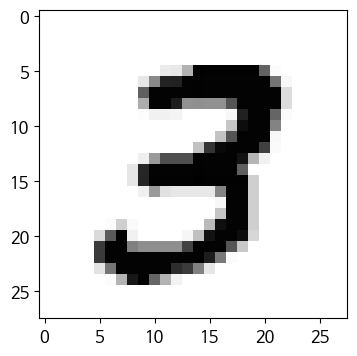

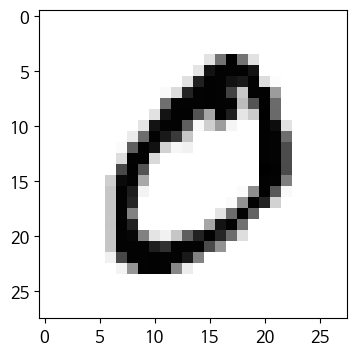

In [ ]:
# tensorflow에서 데이터 불러오기
from tensorflow.keras.datasets.mnist import load_data
# 그래프 라이브러리 불러오기
import matplotlib.pyplot as plt


# 데이터 불러오기
(x_train, y_train), (x_test, y_test) = load_data()

# 학습시간 고려해서 2000건 데이터만 사용하기
x_train = x_train[:2000]
y_train = y_train[:2000]
x_test = x_test[:2000]
y_test = y_test[:2000]


# 샘플 데이터 확인하기
plt.imshow(x_train[7], cmap='Greys')
plt.show()


# 샘플 데이터 확인하기
plt.imshow(x_train[1], cmap='Greys')
plt.show()


# 학습을 위한 2차원 행렬로 변경하기
X_train = x_train.reshape(-1, 784)
X_test = x_test.reshape(-1, 784)

#### (2) 알고리즘 별 학습 및 결과 비교하기

      Iter       Train Loss   Remaining Time 
         1           1.8398            3.37m
         2           1.5879            3.05m
         3           1.4024            3.77m
         4           1.2584            4.62m
         5           1.1338            4.34m
         6           1.0258            4.14m
         7           0.9359            3.86m
         8           0.8556            3.60m
         9           0.7863            3.37m
        10           0.7247            3.25m
        20           0.3653            2.49m
        30           0.2167            1.81m
        40           0.1423            1.47m
        50           0.0982            1.18m
        60           0.0720           53.86s
        70           0.0540           40.36s
        80           0.0410           28.95s
        90           0.0321           14.58s
       100           0.0252            0.00s
의사결정나무: train_acc = 1.0, test_acc = 0.652
랜덤포레스트: train_acc = 1.0, test_acc = 0.875
그라디언트부스팅: train

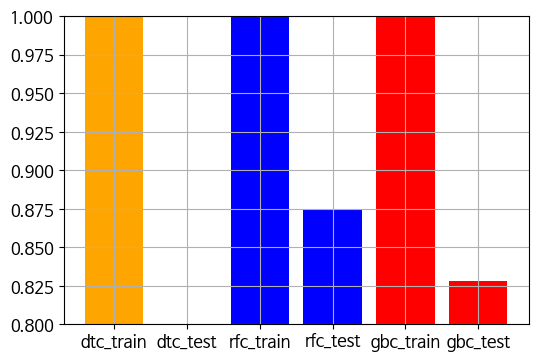

In [ ]:
# 의사결정나무, 랜덤포레스트, 그라디언트부스팅 라이브러리 불러오기
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier


# 의사결정나무 불러오기 및 학습하기
dtc = DecisionTreeClassifier(random_state=0)
dtc.fit(X_train, y_train)


# 의사결정나무 학습 결과 저장하기
acc_train_dtc = dtc.score(X_train,y_train)
acc_test_dtc = dtc.score(X_test,y_test)


# 랜덤포레스트 불러오기 및 학습하기
rfc = RandomForestClassifier(random_state=0)
rfc.fit(X_train, y_train)


# 랜덤포레스트 학습 결과 저장하기
acc_train_rfc = rfc.score(X_train,y_train)
acc_test_rfc = rfc.score(X_test,y_test)


# 그라디언트부스팅 불러오기 및 학습하기
gbc = GradientBoostingClassifier(random_state=0, verbose=1)
gbc.fit(X_train, y_train)


# 그라디언트부스팅 학습 결과 저장하기
acc_train_gbc = gbc.score(X_train,y_train)
acc_test_gbc = gbc.score(X_test,y_test)

# 각 알고리즘별 성능 비교하기
print(f"""의사결정나무: train_acc = {round(acc_train_dtc,3)}, test_acc = {round(acc_test_dtc,3)}""")
print(f"""랜덤포레스트: train_acc = {round(acc_train_rfc,3)}, test_acc = {round(acc_test_rfc,3)}""")
print(f"""그라디언트부스팅: train_acc = {round(acc_train_gbc,3)}, test_acc = {round(acc_test_gbc,3)}""")


# 비교 그래프 그리기
import matplotlib.pyplot as plt
acc_list_x = ['dtc_train', 'dtc_test', 'rfc_train', 'rfc_test', 'gbc_train', 'gbc_test', ]
acc_list_y = [acc_train_dtc, acc_test_dtc, acc_train_rfc, acc_test_rfc, acc_train_gbc, acc_test_gbc]
colors = ['orange', 'orange' , 'blue', 'blue', 'red', 'red']
plt.bar(acc_list_x,acc_list_y, color=colors)
plt.ylim([0.8, 1.0])
plt.grid(True)
plt.show()

### [확인 문제]

#### [Quiz 1] 그래디언트 부스팅 알고리즘으로 n_estimator를 200으로 설정(기본값은 100)하여 학습시켜 보고 기존 그래디언트 부스팅 결과와 비교하는 그래프 코드를 작성하세요.

      Iter       Train Loss   Remaining Time 
         1           1.8398            3.14m
         2           1.5879            3.15m
         3           1.4024            3.15m
         4           1.2584            3.12m
         5           1.1338            3.11m
         6           1.0258            3.09m
         7           0.9359            3.08m
         8           0.8556            3.12m
         9           0.7863            3.21m
        10           0.7247            3.28m
        20           0.3653            3.00m
        30           0.2167            2.87m
        40           0.1423            2.71m
        50           0.0982            2.56m
        60           0.0720            2.39m
        70           0.0540            2.21m
        80           0.0410            2.05m
        90           0.0321            1.88m
       100           0.0252            1.71m
       200           0.0024            0.00s
그라디언트부스팅: train_acc = 1.0, test_acc = 0.828
튜닝 그라디언트부스

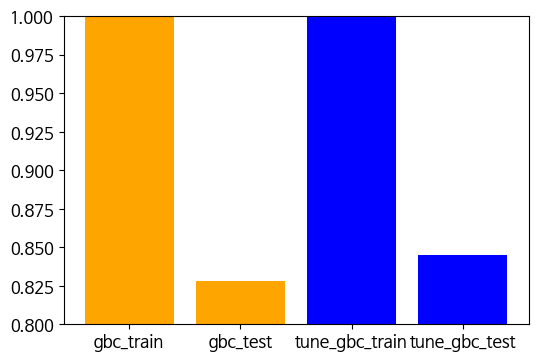

In [ ]:
# 그라디언트부스팅 불러오기 및 학습하기
gbc_200 = GradientBoostingClassifier(random_state=0,
                                 n_estimators=200,
                                verbose=1)
gbc_200.fit(X_train, y_train)


# 그라디언트부스팅 학습 결과 다시 저장하기
acc_train_gbc_200 = gbc_200.score(X_train,y_train)
acc_test_gbc_200 = gbc_200.score(X_test,y_test)

print(f"""그라디언트부스팅: train_acc = {round(acc_train_gbc,3)}, test_acc = {round(acc_test_gbc,3)}""")
print(f"""튜닝 그라디언트부스팅: train_acc = {round(acc_train_gbc_200,3)}, test_acc = {round(acc_test_gbc_200,3)}""")



import matplotlib.pyplot as plt
acc_list_x = ['gbc_train', 'gbc_test', 'tune_gbc_train', 'tune_gbc_test', ]
acc_list_y = [acc_train_gbc, acc_test_gbc, acc_train_gbc_200, acc_test_gbc_200]
colors = ['orange', 'orange' , 'blue', 'blue']
plt.bar(acc_list_x, acc_list_y, color=colors)
plt.ylim([0.8,1.0])
plt.show()


### **[LLM 실습] 부스팅으로 LLM 응답 품질 예측**

In [ ]:
# ============================================================
# [LLM 실습] 부스팅으로 LLM 응답 품질 예측
# HistGradientBoostingClassifier
# ============================================================
# !pip install -q scikit-learn pandas numpy

import numpy as np
import pandas as pd

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_score
from sklearn.inspection import permutation_importance


# ------------------------------------------------------------
# 1. LLM 프롬프트 운영 데이터를 가상으로 생성
# ------------------------------------------------------------
rng = np.random.default_rng(42)

n = 500

df = pd.DataFrame({

    # 프롬프트의 길이
    "프롬프트길이": rng.integers(5, 300, n),

    # Few-shot 예제 개수
    "예시개수": rng.integers(0, 5, n),

    # 역할 지정 여부
    # 0 = 없음, 1 = 있음
    "역할지정": rng.integers(0, 2, n),

    # 출력 형식 지정 여부
    # 0 = 없음, 1 = 있음
    "출력형식명시": rng.integers(0, 2, n),

    # LLM temperature
    "온도": rng.uniform(0, 1.5, n)
})


# ------------------------------------------------------------
# 2. 규칙 + 잡음으로 "만족" 레이블 생성
#
# 실제 프로젝트에서는 이 부분을
# 실제 LLM 운영 로그의 사용자 만족도/성공 여부로 대체
# ------------------------------------------------------------
score = (
      df["예시개수"] * 0.8
    + df["역할지정"] * 1.2
    + df["출력형식명시"] * 1.5
    - df["온도"] * 1.0
    + rng.normal(0, 0.7, n)
)

df["만족"] = (score > score.mean()).astype(int)


# ------------------------------------------------------------
# 3. Feature / Target 분리
# ------------------------------------------------------------
X = df.drop(columns="만족")
y = df["만족"]


print("데이터 크기 :", df.shape)

print("\n데이터 예시")
display(df.head())


# ------------------------------------------------------------
# 4. HistGradientBoosting 학습 및 교차검증
# ------------------------------------------------------------
m = HistGradientBoostingClassifier(
    random_state=0
)

cv_scores = cross_val_score(
    m,
    X,
    y,
    cv=5
)

print("\n5-Fold 정확도")
print(cv_scores)

print("\n평균 정확도:",
      cv_scores.mean().round(4))


# ------------------------------------------------------------
# 5. 전체 데이터 학습
# ------------------------------------------------------------
m.fit(X, y)


# ------------------------------------------------------------
# 6. Permutation Importance
# ------------------------------------------------------------
imp = permutation_importance(
    m,
    X,
    y,
    n_repeats=10,
    random_state=0
)

importance = pd.Series(
    imp.importances_mean,
    index=X.columns
).sort_values(ascending=False)


print("\n==============================")
print("Feature Importance")
print("==============================")

print(importance)

데이터 크기 : (500, 6)

데이터 예시


,프롬프트길이,예시개수,역할지정,출력형식명시,온도,만족
0,31,0,1,1,0.093095,1
1,233,3,1,0,0.687393,1
2,198,4,1,0,0.193545,1
3,134,4,1,0,0.228490,1
4,132,1,0,1,0.948424,0



5-Fold 정확도
[0.8  0.83 0.88 0.85 0.86]

평균 정확도: 0.844

Feature Importance
예시개수      0.3380
온도        0.1762
출력형식명시    0.1426
역할지정      0.1318
프롬프트길이    0.0938
dtype: float64


- ① 가장 중요한 특성은? 실제 프롬프트 작성 원칙과 일치하는가?

Feature Importance 순위
----------------------------------------
1위 : 예시개수       중요도 = 0.3380
2위 : 온도         중요도 = 0.1762
3위 : 출력형식명시     중요도 = 0.1426
4위 : 역할지정       중요도 = 0.1318
5위 : 프롬프트길이     중요도 = 0.0938

가장 중요한 Feature
Feature : 예시개수
중요도  : 0.338

✅ 체크포인트 1 통과
가장 중요한 특성 : 예시개수

프롬프트 작성 원칙
Few-shot 예시는 모델에게 원하는 답변 패턴을 보여줄 수 있다.

✅ 모델 분석 결과와 프롬프트 작성 원칙을 비교해 보세요.


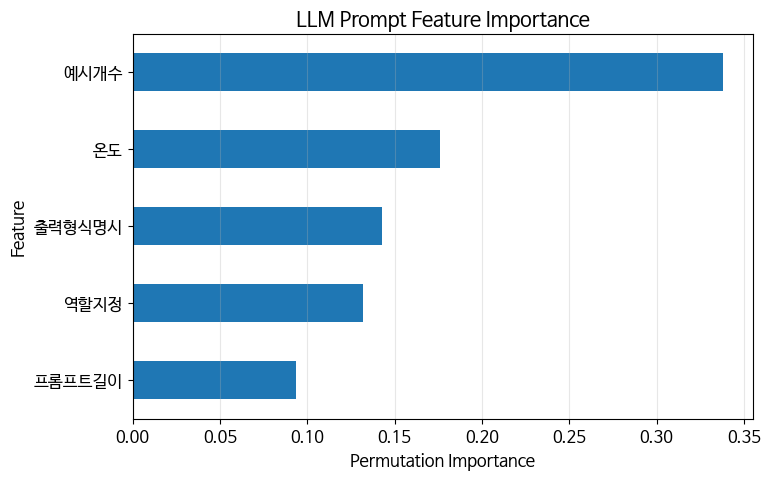

In [ ]:
# ============================================================
# 미션 1
# 가장 중요한 Feature 찾기
# ============================================================

print("Feature Importance 순위")
print("-" * 40)

for rank, (feature, value) in enumerate(
    importance.items(),
    start=1
):
    print(
        f"{rank}위 : {feature:10s} "
        f"중요도 = {value:.4f}"
    )


# 가장 중요한 Feature

top_feature = importance.index[0]
top_value = importance.iloc[0]

print("\n==============================")
print("가장 중요한 Feature")
print("==============================")

print("Feature :", top_feature)
print("중요도  :", round(top_value, 4))


# 테스트

assert top_feature in X.columns
assert top_value >= 0

print("\n✅ 체크포인트 1 통과")


# ============================================================
# Feature와 실제 프롬프트 작성 원칙 비교
# ============================================================

prompt_principles = {

    "예시개수":
        "Few-shot 예시는 모델에게 원하는 답변 패턴을 보여줄 수 있다.",

    "역할지정":
        "역할이나 작업 맥락을 명시하면 모델이 수행해야 할 작업을 명확하게 할 수 있다.",

    "출력형식명시":
        "표, JSON, 목록 등 원하는 출력 형식을 명확하게 지정한다.",

    "온도":
        "낮은 temperature는 일반적으로 출력의 일관성을 높이는 데 도움이 될 수 있다.",

    "프롬프트길이":
        "프롬프트가 길다고 반드시 좋은 것은 아니며 필요한 정보를 명확하게 제공하는 것이 중요하다."
}


print("가장 중요한 특성 :", top_feature)
print("\n프롬프트 작성 원칙")
print(    prompt_principles[top_feature] )
print("\n✅ 모델 분석 결과와 프롬프트 작성 원칙을 비교해 보세요.")


import matplotlib.pyplot as plt

importance.sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)
plt.title( "LLM Prompt Feature Importance")
plt.xlabel( "Permutation Importance" )
plt.ylabel( "Feature" )
plt.grid( axis="x", alpha=0.3 )
plt.show()